# Good Seed: estimación de edad a partir de fotografías del rostro

La cadena de supermercados Good Seed quiere evaluar si la visión artificial puede ayudarle a no vender alcohol a menores de edad. Las cajas tienen cámaras que se activan cuando una persona compra alcohol; el objetivo es construir un modelo que estime la edad de una persona a partir de una foto de su rostro.

- **Tipo de problema:** regresión (se predice un número: la edad en años).
- **Métrica:** MAE (*Mean Absolute Error*, error absoluto medio), en años. Meta: **MAE ≤ 8** en el conjunto de prueba.
- **Datos:** conjunto APPA-REAL (ChaLearn Looking at People): `labels.csv` (`file_name`, `real_age`) y la carpeta `final_files/` con las fotografías.
- **Entorno:** el proyecto se trabajó en una computadora local (Apple M5, 16 GB de RAM), con TensorFlow 2.21 y Keras 3.15, entrenando solo con CPU. Los datos están en la carpeta local `data/` (en la plataforma: `/datasets/faces/`).

## Inicialización

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib import font_manager
from matplotlib.patches import Patch
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

RANDOM_STATE = 12345
VALIDATION_SPLIT = 0.25
TAMANO_IMAGEN = 224
TAMANO_LOTE = 32

RAIZ = Path.cwd()
while not (RAIZ / 'data' / 'labels.csv').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
PATH_DATA = RAIZ / 'data'
PATH_LABELS = PATH_DATA / 'labels.csv'
PATH_IMAGES = PATH_DATA / 'final_files'

for ruta in sorted((RAIZ / 'assets' / 'fuentes').glob('*.ttf')):
    font_manager.fontManager.addfont(str(ruta))
plt.rcParams['font.family'] = 'Raleway'

## Carga los datos

El conjunto de datos se almacena en la carpeta `/datasets/faces/` 
- La carpeta `final_files` con 7600 fotos 
- El archivo `labels.csv` con etiquetas, con dos columnas: `file_name` y `real_age` 
Dado que el número de archivos de imágenes es bastante elevado, se recomienda evitar leerlos todos a la vez, ya que esto consumiría muchos recursos computacionales. Te recomendamos crear un generador con ImageDataGenerator. Este método se explicó en el capítulo 3, lección 7 de este curso.

El archivo de etiqueta se puede cargar como un archivo CSV habitual.

In [2]:
labels = pd.read_csv(PATH_LABELS)
display(labels.head())

datagen = ImageDataGenerator(rescale=1/255)
gen_flow = datagen.flow_from_dataframe(
    dataframe=labels,
    directory=str(PATH_IMAGES),
    x_col='file_name',
    y_col='real_age',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw',
    seed=RANDOM_STATE,
)

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


Found 7591 validated image filenames.


## EDA

### 1. Integridad del conjunto

Se verifica que cada etiqueta tenga su imagen, que cada imagen tenga su etiqueta y que no haya nombres duplicados ni valores nulos. Los archivos ocultos del sistema (por ejemplo, `.DS_Store` en macOS) se excluyen del conteo de imágenes.

In [3]:
print(f'Filas: {labels.shape[0]:,} | Columnas: {labels.shape[1]}')
labels.info()

archivos = {ruta.name for ruta in PATH_IMAGES.iterdir() if ruta.is_file() and not ruta.name.startswith('.')}
etiquetas_sin_imagen = (~labels['file_name'].isin(archivos)).sum()
imagenes_sin_etiqueta = len(archivos - set(labels['file_name']))
duplicados = labels['file_name'].duplicated().sum()
nulos = labels.isna().sum().sum()

print(f'\nImágenes en la carpeta: {len(archivos):,}')
print(f'Etiquetas sin imagen: {etiquetas_sin_imagen}')
print(f'Imágenes sin etiqueta: {imagenes_sin_etiqueta}')
print(f'Nombres de archivo duplicados: {duplicados}')
print(f'Valores nulos: {nulos}')

Filas: 7,591 | Columnas: 2
<class 'pandas.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  7591 non-null   str  
 1   real_age   7591 non-null   int64
dtypes: int64(1), str(1)
memory usage: 118.7 KB

Imágenes en la carpeta: 7,591
Etiquetas sin imagen: 0
Imágenes sin etiqueta: 0
Nombres de archivo duplicados: 0
Valores nulos: 0


### 2. Distribución de edades

Las edades se agrupan en siete rangos. Los grupos 13-17 y 18-24 son los de mayor interés: ahí se toma la decisión de venta y un error de pocos años cambia el resultado legal. El parámetro `include_lowest=True` incluye en el primer grupo la edad mínima del conjunto, que de otro modo quedaría fuera del intervalo.

In [4]:
rangos = [0, 12, 17, 24, 34, 49, 64, np.inf]
nombres = ['0-12', '13-17', '18-24', '25-34', '35-49', '50-64', '65+']
labels['grupo'] = pd.cut(labels['real_age'], bins=rangos, labels=nombres, include_lowest=True)

display(labels['real_age'].describe().round(1).to_frame('real_age'))

resumen = labels['grupo'].value_counts().sort_index().to_frame('fotos')
resumen['porcentaje'] = (resumen['fotos'] / len(labels) * 100).round(1)
display(resumen)

print('Edades con más fotos:')
display(labels['real_age'].value_counts().head(10).to_frame('fotos'))

,real_age
count,7591.0
mean,31.2
std,17.1
min,1.0
25%,20.0
50%,29.0
75%,41.0
max,100.0


,fotos,porcentaje
grupo,,
0-12,815,10.7
13-17,688,9.1
18-24,1297,17.1
25-34,2071,27.3
35-49,1584,20.9
50-64,789,10.4
65+,347,4.6


Edades con más fotos:


,fotos
real_age,
30,317
25,315
27,229
26,226
28,217
23,213
24,211
18,193
16,193


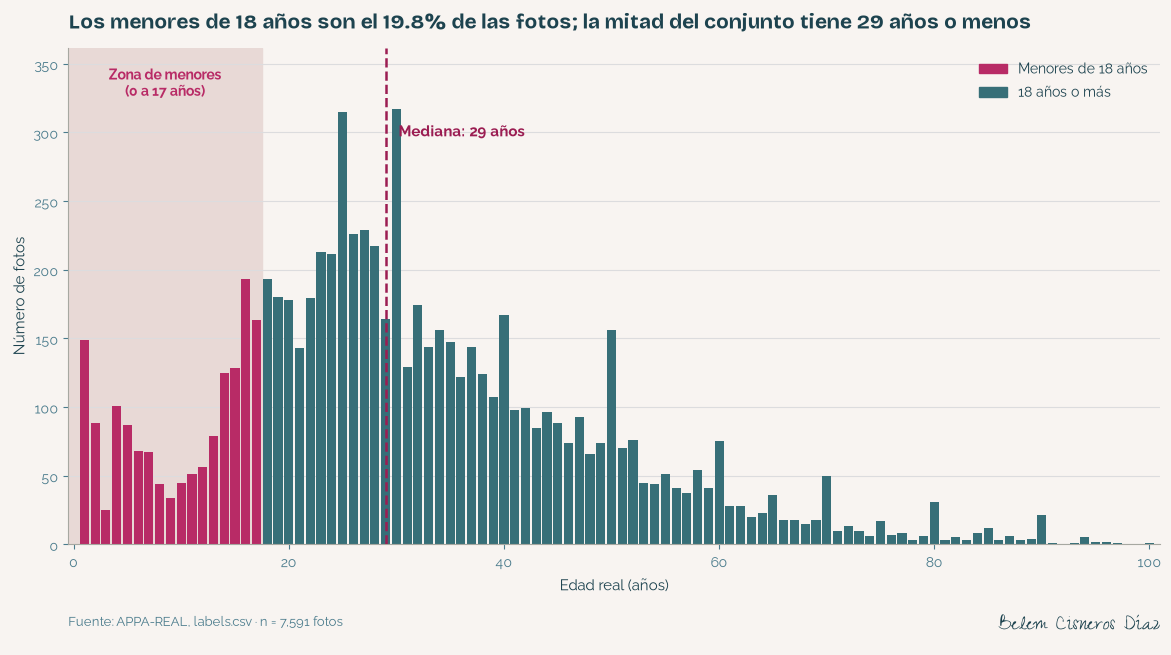

In [5]:
colores = {
    'fondo': '#F8F4F1',
    'banda_menores': '#E8D9D6',
    'rejilla': '#DCDCDE',
    'ejes': '#A7A8A1',
    'texto': '#1D434F',
    'secundario': '#4A7B8C',
    'adultos': '#376F78',
    'menores': '#B82B66',
    'mediana': '#9B1D52',
}

edades = labels['real_age']
conteos = edades.value_counts().sort_index()
mediana = edades.median()
pct_menores = (edades < 18).mean() * 100
n = len(labels)
tope = conteos.max()

fig, ax = plt.subplots(figsize=(12, 6.8))
fig.patch.set_facecolor(colores['fondo'])
ax.set_facecolor(colores['fondo'])

ax.axvspan(-0.5, 17.5, color=colores['banda_menores'], zorder=0)
ax.bar(conteos.index, conteos.values, width=0.85, zorder=2,
       color=[colores['menores'] if edad < 18 else colores['adultos'] for edad in conteos.index])

ax.text(8.5, tope * 1.06, 'Zona de menores\n(0 a 17 años)', ha='center', va='center',
        color=colores['menores'], fontsize=10, fontweight='bold')

ax.axvline(mediana, color=colores['mediana'], linewidth=1.8, linestyle='--', zorder=3)
ax.text(mediana + 1.2, tope * 0.97, f'Mediana: {mediana:.0f} años', va='top',
        color=colores['mediana'], fontsize=11, fontweight='bold')

ax.set_title(f'Los menores de 18 años son el {pct_menores:.1f}% de las fotos; '
             f'la mitad del conjunto tiene {mediana:.0f} años o menos',
             loc='left', fontsize=15, fontweight='bold', color=colores['texto'],
             fontfamily='Bricolage Grotesque', pad=14)
ax.set_xlabel('Edad real (años)', color=colores['texto'], fontsize=11)
ax.set_ylabel('Número de fotos', color=colores['texto'], fontsize=11)
ax.set_xlim(-0.5, edades.max() + 1)
ax.set_ylim(0, tope * 1.14)

ax.legend(handles=[Patch(color=colores['menores'], label='Menores de 18 años'),
                   Patch(color=colores['adultos'], label='18 años o más')],
          frameon=False, loc='upper right', fontsize=10, labelcolor=colores['texto'])

for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(colores['ejes'])
ax.tick_params(colors=colores['secundario'])
ax.grid(axis='y', color=colores['rejilla'], linewidth=0.8)
ax.set_axisbelow(True)

fig.subplots_adjust(left=0.07, right=0.98, top=0.88, bottom=0.15)
fig.text(0.07, 0.03, f'Fuente: APPA-REAL, labels.csv · n = {n:,} fotos',
         color=colores['secundario'], fontsize=9)
fig.text(0.98, 0.025, 'Belem Cisneros Díaz', ha='right', color=colores['texto'],
         fontsize=17, fontfamily='Zeyada')
plt.show()

### 3. Características de las imágenes

Se revisan las 7,591 imágenes completas, no una muestra. Abrir un archivo con PIL (*Python Imaging Library*, biblioteca de imágenes de Python) lee solo su encabezado, donde están el tamaño y el modo de color, sin cargar los píxeles; por eso recorrer el conjunto completo toma segundos. El **modo** indica cómo se guarda el color: `RGB` (*Red, Green, Blue*, rojo, verde y azul) son tres canales de color; `L` es un solo canal en escala de grises. La **proporción** es el ancho dividido entre el alto: 1 significa una imagen cuadrada.

In [6]:
propiedades = []
for nombre in labels.loc[labels['file_name'].isin(archivos), 'file_name']:
    with Image.open(PATH_IMAGES / nombre) as imagen:
        propiedades.append({'ancho': imagen.size[0], 'alto': imagen.size[1], 'modo': imagen.mode})
propiedades = pd.DataFrame(propiedades)
propiedades['proporcion'] = propiedades['ancho'] / propiedades['alto']

display(propiedades[['ancho', 'alto', 'proporcion']].describe().round(2))
display(propiedades['modo'].value_counts().to_frame('imágenes'))

,ancho,alto,proporcion
count,7591.00,7591.00,7591.00
mean,464.73,464.09,1.00
std,330.83,331.29,0.07
min,47.00,47.00,0.47
25%,220.00,220.00,1.00
50%,385.00,384.00,1.00
75%,632.00,632.00,1.00
max,4466.00,4466.00,2.99


,imágenes
modo,
RGB,7591


### 4. Muestra de fotos por edad

Se eligen 15 fotos, una por cada edad objetivo entre 2 y 90 años, con mayor densidad alrededor de los 18 años. Cuando no existe una foto con la edad exacta se toma la edad disponible más cercana, y una foto ya elegida no se repite. Las imágenes en escala de grises se convierten a RGB solo para mostrarlas; sin esa conversión, Matplotlib las pintaría con una escala de colores artificial.



In [7]:
colores = {
    'fondo': '#F8F4F1',
    'texto': '#1D434F',
    'secundario': '#4A7B8C',
    'menores': '#B82B66',
}

edades_objetivo = [2, 6, 10, 14, 16, 17, 18, 20, 25, 30, 40, 50, 60, 75, 90]
disponibles = labels[labels['file_name'].isin(archivos)]
usados = set()
filas = []
for edad in edades_objetivo:
    candidatas = disponibles[~disponibles['file_name'].isin(usados)]
    cercana = candidatas.loc[(candidatas['real_age'] - edad).abs().idxmin(), 'real_age']
    fila = candidatas[candidatas['real_age'] == cercana].sample(1, random_state=RANDOM_STATE)
    usados.update(fila['file_name'])
    filas.append(fila)
muestra_fotos = pd.concat(filas)

fig, axes = plt.subplots(3, 5, figsize=(15, 10.5))
fig.patch.set_facecolor(colores['fondo'])

tamanos = []
for ax, (_, fila) in zip(axes.ravel(), muestra_fotos.iterrows()):
    with Image.open(PATH_IMAGES / fila['file_name']) as imagen:
        tamanos.append(imagen.size)
        ax.imshow(imagen.convert('RGB'))
        tamano = f'{imagen.size[0]}×{imagen.size[1]} px'
    es_menor = fila['real_age'] < 18
    ax.set_title(f'{fila["real_age"]} años · {tamano}', fontsize=11,
                 color=colores['menores'] if es_menor else colores['texto'],
                 fontweight='bold' if es_menor else 'normal')
    ax.axis('off')

tamanos_muestra = len(set(tamanos))
consecuencia = ('el generador deberá llevarlas a un tamaño común' if tamanos_muestra > 1
                else 'todas comparten el mismo tamaño')
fig.suptitle(f'{len(muestra_fotos)} fotos de {muestra_fotos["real_age"].min()} a '
             f'{muestra_fotos["real_age"].max()} años con {tamanos_muestra} tamaños distintos: '
             f'{consecuencia}',
             x=0.01, ha='left', fontsize=15, fontweight='bold', color=colores['texto'],
             fontfamily='Bricolage Grotesque')
fig.subplots_adjust(left=0.01, right=0.99, top=0.91, bottom=0.07, hspace=0.25, wspace=0.05)
fig.text(0.01, 0.02, 'Fuente: APPA-REAL, final_files · una foto aleatoria por edad seleccionada; '
         'edades de menores de 18 años en magenta y negritas',
         color=colores['secundario'], fontsize=9)
fig.text(0.99, 0.015, 'Belem Cisneros Díaz', ha='right', color=colores['texto'],
         fontsize=17, fontfamily='Zeyada')
plt.show()

*Salida omitida en la versión pública para proteger la privacidad de las personas fotografiadas; se genera al ejecutar la celda con los datos originales.*

### 5. Orden del archivo y composición de la división

`flow_from_dataframe` con `validation_split=0.25` no elige al azar: asigna a **validación el primer 25% de las filas** del DataFrame (la tabla de pandas) y a **entrenamiento el 75% restante**. Si el archivo estuviera ordenado por edad, cada conjunto cubriría un rango de edades distinto y el MAE de validación no representaría al modelo.

Esta sección hace dos cosas:
1. **Mide el riesgo en el orden original:** compara las edades del primer 25% contra el resto y calcula la correlación de rangos de Spearman entre la posición de la fila y la edad. Esta correlación va de −1 a 1 e indica si, al avanzar en el archivo, la edad tiende a subir (positiva), a bajar (negativa) o no sigue una tendencia (cercana a 0).
2. **Muestra la división que se usará:** las filas se mezclan con `RANDOM_STATE = 12345`, igual que en `load_train` y `load_test`, y se cuenta cuántas fotos de cada grupo de edad caen en entrenamiento y en validación. Esta composición es exacta mientras no haya etiquetas sin imagen (sección 1), porque el generador descarta esas filas antes de dividir.

In [8]:
corte = int(len(labels) * VALIDATION_SPLIT)

orden_original = pd.DataFrame({
    'primer 25% del archivo': labels['real_age'].iloc[:corte].describe(),
    '75% restante': labels['real_age'].iloc[corte:].describe(),
}).round(1)
display(orden_original)

correlacion_orden = pd.Series(np.arange(len(labels)), index=labels.index).corr(labels['real_age'], method='spearman')
print(f'Correlación de Spearman entre la posición de la fila y la edad: {correlacion_orden:.3f}\n')

mezclado = labels.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
mezclado['conjunto'] = np.where(mezclado.index < corte, 'validación', 'entrenamiento')

composicion = pd.crosstab(mezclado['grupo'], mezclado['conjunto'])[['entrenamiento', 'validación']]
composicion['% en validación'] = (composicion['validación'] / composicion.sum(axis=1) * 100).round(1)
display(composicion)

menores_validacion = (mezclado.loc[mezclado['conjunto'] == 'validación', 'real_age'] < 18).sum()
fotos_entrenamiento = (mezclado['conjunto'] == 'entrenamiento').sum()
print(f'Fotos de entrenamiento: {fotos_entrenamiento:,} | Fotos de validación: {corte:,}')
print(f'Menores de 18 años en validación: {menores_validacion} '
      f'(el 1% de ellos equivale a {menores_validacion / 100:.1f} personas)')

,primer 25% del archivo,75% restante
count,1897.0,5694.0
mean,29.6,31.7
std,16.8,17.2
min,1.0,1.0
25%,18.0,20.0
50%,27.0,29.0
75%,40.0,41.0
max,90.0,100.0


Correlación de Spearman entre la posición de la fila y la edad: 0.055



conjunto,entrenamiento,validación,% en validación
grupo,,,
0-12,629,186,22.8
13-17,508,180,26.2
18-24,960,337,26.0
25-34,1574,497,24.0
35-49,1173,411,25.9
50-64,580,209,26.5
65+,270,77,22.2


Fotos de entrenamiento: 5,694 | Fotos de validación: 1,897
Menores de 18 años en validación: 366 (el 1% de ellos equivale a 3.7 personas)


### 6. Hallazgos

Los valores de esta sección se calculan directamente a partir de las salidas anteriores.

In [9]:
asimetria = edades.skew()
sentido = 'hacia edades altas' if asimetria > 0 else 'hacia edades bajas'
grupo_mayor = resumen['fotos'].idxmax()
grupo_menor = resumen['fotos'].idxmin()
tamanos_distintos = propiedades[['ancho', 'alto']].drop_duplicates().shape[0]
pct_no_rgb = (propiedades['modo'] != 'RGB').mean() * 100
diferencia_orden = orden_original.loc['mean', 'primer 25% del archivo'] - orden_original.loc['mean', '75% restante']

texto = f'''
**Tamaño e integridad.** El conjunto tiene **{len(labels):,} fotografías** con su edad real y **{len(archivos):,} imágenes** en la carpeta. Hay **{etiquetas_sin_imagen}** etiquetas sin imagen, **{imagenes_sin_etiqueta}** imágenes sin etiqueta, **{duplicados}** nombres duplicados y **{nulos}** valores nulos.

**Distribución de edades.** La edad va de **{edades.min()}** a **{edades.max()} años**, con media de **{edades.mean():.1f}** y mediana de **{edades.median():.0f}**. La asimetría es de **{asimetria:.2f}**: la distribución se extiende {sentido}.

**Representación por grupo.** El grupo con más fotos es **{grupo_mayor}** ({resumen.loc[grupo_mayor, 'porcentaje']}%) y el que menos tiene es **{grupo_menor}** ({resumen.loc[grupo_menor, 'porcentaje']}%). En la zona de decisión de venta, el grupo **13-17** reúne el **{resumen.loc['13-17', 'porcentaje']}%** de las fotos y el **18-24** el **{resumen.loc['18-24', 'porcentaje']}%**. Los menores de 18 años son el **{(edades < 18).mean() * 100:.1f}%** del conjunto.

**Imágenes.** En las {len(propiedades):,} imágenes, el ancho va de **{propiedades['ancho'].min()}** a **{propiedades['ancho'].max()} px** y el alto de **{propiedades['alto'].min()}** a **{propiedades['alto'].max()} px**, con **{tamanos_distintos:,}** combinaciones distintas de tamaño. El **{pct_no_rgb:.1f}%** no está en modo RGB.

**Orden del archivo.** En el orden original, la edad promedio del primer 25% difiere en **{diferencia_orden:+.1f} años** de la del resto, y la correlación de Spearman entre la posición de la fila y la edad es **{correlacion_orden:.3f}**.

**División tras la mezcla.** Con `RANDOM_STATE = 12345`, entrenamiento recibe **{fotos_entrenamiento:,}** fotos y validación **{corte:,}**. En validación hay **{menores_validacion}** menores de 18 años: un 1% de menores no detectados equivale a **{menores_validacion / 100:.1f}** personas.
'''
display(Markdown(texto))


**Tamaño e integridad.** El conjunto tiene **7,591 fotografías** con su edad real y **7,591 imágenes** en la carpeta. Hay **0** etiquetas sin imagen, **0** imágenes sin etiqueta, **0** nombres duplicados y **0** valores nulos.

**Distribución de edades.** La edad va de **1** a **100 años**, con media de **31.2** y mediana de **29**. La asimetría es de **0.73**: la distribución se extiende hacia edades altas.

**Representación por grupo.** El grupo con más fotos es **25-34** (27.3%) y el que menos tiene es **65+** (4.6%). En la zona de decisión de venta, el grupo **13-17** reúne el **9.1%** de las fotos y el **18-24** el **17.1%**. Los menores de 18 años son el **19.8%** del conjunto.

**Imágenes.** En las 7,591 imágenes, el ancho va de **47** a **4466 px** y el alto de **47** a **4466 px**, con **2,293** combinaciones distintas de tamaño. El **0.0%** no está en modo RGB.

**Orden del archivo.** En el orden original, la edad promedio del primer 25% difiere en **-2.1 años** de la del resto, y la correlación de Spearman entre la posición de la fila y la edad es **0.055**.

**División tras la mezcla.** Con `RANDOM_STATE = 12345`, entrenamiento recibe **5,694** fotos y validación **1,897**. En validación hay **366** menores de 18 años: un 1% de menores no detectados equivale a **3.7** personas.


### Conclusiones

**Hallazgos del análisis exploratorio**

1. **Tamaño e integridad.** El conjunto contiene 7,591 fotografías con su edad real (la descripción del proyecto indica 7,600). Cada etiqueta corresponde a una imagen existente y cada imagen tiene etiqueta; no hay nombres duplicados ni valores nulos.
2. **Distribución de edades.** Las edades van de 1 a 100 años, con media de 31.2, mediana de 29 y desviación estándar de 17.1. La asimetría de 0.73 indica una concentración en adultos jóvenes y una cola larga hacia edades altas.
3. **Representación por grupo.** El grupo 25-34 es el más numeroso (27.3%) y el 65+ el más escaso (4.6%). En la franja relevante para la venta de alcohol hay 688 fotografías de 13 a 17 años (9.1%) y 1,297 de 18 a 24 (17.1%). Los menores de 18 años suman 1,503 imágenes (19.8%).
4. **Concentración en edades redondas.** Las edades más frecuentes son 30 (317 fotografías) y 25 (315), muy por encima de las edades contiguas (217 a 229 entre los 26 y 28 años). El patrón es consistente con el redondeo a múltiplos de 5 típico de edades declaradas.
5. **Características de las imágenes.** Todas están en RGB. Su tamaño va de 47 a 4,466 píxeles por lado, con 2,293 combinaciones distintas y una mediana de 385 × 384. La proporción ancho/alto tiene mediana de 1.00: son recortes prácticamente cuadrados centrados en el rostro.
6. **Orden del archivo.** Las filas de `labels.csv` no están en orden aleatorio: el primer 25% tiene una edad media de 29.6 años frente a 31.7 del resto (−2.1 años), con una correlación de Spearman de 0.055 entre posición y edad.
7. **División tras la mezcla.** Con `RANDOM_STATE = 12345`, el conjunto de entrenamiento queda con 5,694 fotografías y el de validación con 1,897. Cada grupo de edad aporta entre el 22% y el 26.5% de sus imágenes a validación, que incluye 366 menores de 18 años.

**Implicaciones para el entrenamiento**

- **Problema y métrica.** La edad es una variable continua, por lo que se plantea una regresión evaluada con el MAE (error absoluto medio, en años). La meta del proyecto es un MAE ≤ 8; un valor menor a 7 se considera un resultado sobresaliente, y el artículo de APPA-REAL reporta 5.4 como el mínimo alcanzado.
- **Mezcla antes de dividir.** `flow_from_dataframe` asigna a validación el primer 25% de las filas. Dado que el archivo no está en orden aleatorio, las filas se mezclan antes de crear los generadores para que ambos conjuntos cubran todo el rango de edades.
- **División 75/25.** Se reserva el 25% para validación (frente al 20% de la lección) para contar con más menores de edad en la evaluación del umbral de venta.
- **Evaluación por grupo.** Por la desigual representación de edades, además del MAE global se analiza el error y el sesgo (edad estimada − edad real) por grupo, con atención especial a los grupos 13-17 y 18-24.
- **Uso como filtro.** Un error de varios años puede hacer pasar a un menor de 17 como adulto, por lo que el modelo se evalúa como herramienta para decidir a quién pedir identificación, no para autorizar la venta.
- **Preprocesamiento.** Las imágenes se redimensionan a 224 × 224 píxeles, el tamaño de entrada de ResNet50, y se normalizan dividiendo entre 255. Las fotografías más pequeñas pierden nitidez al ampliarse; al ser recortes casi cuadrados, el redimensionamiento no deforma los rostros.
- **Aumento de datos.** Solo se aplica reflejo horizontal en entrenamiento, ya que un rostro reflejado sigue siendo plausible frente a una cámara de caja; rotaciones grandes o reflejos verticales no lo son.
- **Modelo.** Se parte de ResNet50 preentrenada en ImageNet. Como ImageNet no es un conjunto de rostros, se compara una versión con la red congelada contra un ajuste fino completo, y ambas contra un modelo constante que predice la mediana de edad.

## Modelado

Define las funciones necesarias para entrenar tu modelo en la plataforma GPU y crea un solo script que las contenga todas junto con la sección de inicialización.

Para facilitar esta tarea, puedes definirlas en este notebook y ejecutar un código listo en la siguiente sección para componer automáticamente el script.

Los revisores del proyecto también verificarán las definiciones a continuación, para que puedan comprender cómo construiste el modelo.

In [10]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint

`leer_etiquetas` lee `labels.csv` y mezcla sus filas con `RANDOM_STATE` antes de dividir. Es necesaria porque `flow_from_dataframe` con `validation_split=0.25` asigna a validación el **primer 25% de las filas**, y el archivo original no está en orden aleatorio (sección 5 del EDA). `load_train` y `load_test` la usan ambas, así que parten del mismo orden y la división es complementaria.

In [11]:
def leer_etiquetas(path):

    """
    Lee labels.csv y mezcla sus filas antes de dividir.
    """

    labels = pd.read_csv(os.path.join(path, 'labels.csv'))

    return labels.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

In [12]:
def load_train(path):

    """
    Carga la parte de entrenamiento del conjunto de datos desde la ruta.
    """

    train_datagen = ImageDataGenerator(rescale=1/255, horizontal_flip=True, validation_split=VALIDATION_SPLIT)
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=leer_etiquetas(path),
        directory=os.path.join(path, 'final_files'),
        x_col='file_name',
        y_col='real_age',
        target_size=(TAMANO_IMAGEN, TAMANO_IMAGEN),
        batch_size=TAMANO_LOTE,
        class_mode='raw',
        subset='training',
        seed=RANDOM_STATE,
    )

    return train_gen_flow

In [13]:
def load_test(path):

    """
    Carga la parte de validación/prueba del conjunto de datos desde la ruta
    """

    test_datagen = ImageDataGenerator(rescale=1/255, validation_split=VALIDATION_SPLIT)
    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=leer_etiquetas(path),
        directory=os.path.join(path, 'final_files'),
        x_col='file_name',
        y_col='real_age',
        target_size=(TAMANO_IMAGEN, TAMANO_IMAGEN),
        batch_size=TAMANO_LOTE,
        class_mode='raw',
        subset='validation',
        shuffle=False,
        seed=RANDOM_STATE,
    )

    return test_gen_flow

In [14]:
def create_model(input_shape):

    """
    Define el modelo
    """

    backbone = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    model = Sequential(name='modelo_2')
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='mse', metrics=['mae'])

    return model

In [15]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    """
    Entrena el modelo dados los parámetros
    """

    callbacks = [
        EarlyStopping(monitor='val_mae', mode='min', patience=3, restore_best_weights=True),
        ModelCheckpoint(f'models/{model.name}.keras', monitor='val_mae', mode='min', save_best_only=True),
        CSVLogger(f'resultados/registro_{model.name}.csv'),
    ]
    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        callbacks=callbacks,
        verbose=2,
    )

    return model

**Parámetros del modelo y por qué se eligieron**

| Parámetro | Valor | Motivo |
|---|---|---|
| Red base | ResNet50 con pesos de ImageNet, sin capa superior | Red profunda ya entrenada en 1.2 millones de imágenes; sus filtros detectan bordes, texturas y formas que se reutilizan para el rostro |
| Capas entrenables | Todas (ajuste fino completo) | ImageNet no es un conjunto de rostros: el ajuste fino adapta los filtros a rasgos asociados con la edad |
| Cabeza | `GlobalAveragePooling2D` + `Dense(1, activation='relu')` | Resume cada uno de los 2,048 mapas de características en un número y los combina en una sola salida; ReLU impide edades negativas |
| Pérdida | MSE (error cuadrático medio) | Su gradiente es proporcional al error, lo que acelera el entrenamiento; TripleTen señala que con MSE la red entrena más rápido |
| Métrica | MAE | Se interpreta directamente en años; es la métrica de la meta |
| Optimizador | Adam, tasa 0.0001 | Menor que la de la lección (0.0005) porque se actualizan los 23.6 millones de parámetros de ResNet50: pasos grandes destruirían lo aprendido en ImageNet |
| Validación | 25% (lección: 20%) | Más fotos de menores en validación para estimar la política de umbral |
| Lote | 32 (lección: 16) | Valor del generador sugerido por TripleTen; cabe en 16 GB de RAM |
| Aumento | Solo reflejo horizontal en entrenamiento | Una cara reflejada es plausible frente a una cámara de caja; una cara de cabeza no |
| Épocas | Hasta 20, con parada temprana (paciencia 3 sobre `val_mae`, restaura los mejores pesos) | Detiene el entrenamiento cuando deja de mejorar en validación, en lugar de fijar un número arbitrario (lección: 3) |
| Guardado | Mejor modelo en `models/` (`.keras`) y registro por época en `resultados/` (CSV) | Conservar el mejor modelo y la evidencia de cada época |

## Prepara el script para ejecutarlo en la plataforma GPU

Una vez que hayas definido las funciones necesarias, puedes redactar un script para la plataforma GPU, descargarlo a través del menú "File|Open..." (Archivo|Abrir) y cargarlo más tarde para ejecutarlo en la plataforma GPU.

Nota: el script debe incluir también la sección de inicialización. A continuación se muestra un ejemplo.

In [16]:
# prepara un script para ejecutarlo en la plataforma GPU

init_str = """
import os

import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint

RANDOM_STATE = 12345
VALIDATION_SPLIT = 0.25
TAMANO_IMAGEN = 224
TAMANO_LOTE = 32
"""

import inspect

with open(RAIZ / 'script' / 'run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [leer_etiquetas, load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

La plataforma GPU de TripleTen no fue viable para este proyecto, así que el entrenamiento se ejecutó en la computadora local, solo con CPU. Se usó el script `script/entrenar.py`, que importa exactamente las mismas funciones mostradas arriba desde el paquete `src/` del proyecto, las lanza en segundo plano y guarda la salida completa de la terminal en `resultados/salida_modelo_2.txt`. La celda anterior genera igualmente `script/run_model_on_gpu.py` con la sección de inicialización y las funciones, como pide la plantilla. Ninguna celda de este notebook vuelve a entrenar.

### El resultado

Coloca el resultado de la plataforma GPU como una celda Markdown aquí.

**Modelo 2 · ResNet50 con ajuste fino completo.** Salida completa de la terminal (`resultados/salida_modelo_2.txt`), entrenado en CPU local con `script/entrenar.py`:

```
Modelo 2 | imagen 224x224 | lote 32 | prueba: False
Found 5694 validated image filenames.
Found 1897 validated image filenames.
Epoch 1/20
178/178 - 454s - 3s/step - loss: 223.9347 - mae: 10.6859 - val_loss: 865.3867 - val_mae: 24.5829
Epoch 2/20
178/178 - 425s - 2s/step - loss: 76.0931 - mae: 6.5694 - val_loss: 643.2697 - val_mae: 20.0703
Epoch 3/20
178/178 - 431s - 2s/step - loss: 53.4222 - mae: 5.5460 - val_loss: 301.0479 - val_mae: 12.9217
Epoch 4/20
178/178 - 437s - 2s/step - loss: 37.8368 - mae: 4.7025 - val_loss: 175.4611 - val_mae: 9.7750
Epoch 5/20
178/178 - 426s - 2s/step - loss: 31.9424 - mae: 4.2681 - val_loss: 140.1494 - val_mae: 8.9031
Epoch 6/20
178/178 - 469s - 3s/step - loss: 24.2343 - mae: 3.7426 - val_loss: 82.7659 - val_mae: 6.7096
Epoch 7/20
178/178 - 469s - 3s/step - loss: 21.3669 - mae: 3.5055 - val_loss: 102.2753 - val_mae: 7.5801
Epoch 8/20
178/178 - 426s - 2s/step - loss: 17.9428 - mae: 3.2147 - val_loss: 78.2261 - val_mae: 6.4996
Epoch 9/20
178/178 - 431s - 2s/step - loss: 16.3537 - mae: 3.1035 - val_loss: 83.3720 - val_mae: 6.7714
Epoch 10/20
178/178 - 423s - 2s/step - loss: 15.2702 - mae: 2.9990 - val_loss: 94.0829 - val_mae: 7.1857
Epoch 11/20
178/178 - 431s - 2s/step - loss: 13.3050 - mae: 2.8001 - val_loss: 78.0828 - val_mae: 6.3933
Epoch 12/20
178/178 - 428s - 2s/step - loss: 14.2882 - mae: 2.8714 - val_loss: 77.0343 - val_mae: 6.5360
Epoch 13/20
178/178 - 434s - 2s/step - loss: 13.2167 - mae: 2.7884 - val_loss: 79.7712 - val_mae: 6.5765
Epoch 14/20
178/178 - 437s - 2s/step - loss: 12.5396 - mae: 2.6939 - val_loss: 71.8584 - val_mae: 6.3037
Epoch 15/20
178/178 - 428s - 2s/step - loss: 10.9114 - mae: 2.5214 - val_loss: 86.4176 - val_mae: 6.8074
Epoch 16/20
178/178 - 429s - 2s/step - loss: 12.0532 - mae: 2.6262 - val_loss: 90.5532 - val_mae: 7.0195
Epoch 17/20
178/178 - 428s - 2s/step - loss: 12.1677 - mae: 2.6645 - val_loss: 79.4245 - val_mae: 6.5235
Tiempo de entrenamiento: 123.4 min
MAE de validación del modelo 2: 6.3037 (n = 1,897)
Tiempo total: 124.0 min
```

**Modelo 1 · ResNet50 congelada (solo se entrena la cabeza).** Salida completa de la terminal (`resultados/salida_modelo_1.txt`):

```
Modelo 1 | imagen 224x224 | lote 32 | prueba: False
Found 5694 validated image filenames.
Found 1897 validated image filenames.
Epoch 1/5
178/178 - 123s - 689ms/step - loss: 578.1471 - mae: 18.5361 - val_loss: 303.7182 - val_mae: 13.0803
Epoch 2/5
178/178 - 115s - 646ms/step - loss: 300.0117 - mae: 13.2009 - val_loss: 286.2285 - val_mae: 13.1694
Epoch 3/5
178/178 - 115s - 646ms/step - loss: 296.6467 - mae: 13.3031 - val_loss: 285.9202 - val_mae: 13.2366
Epoch 4/5
178/178 - 116s - 649ms/step - loss: 296.5015 - mae: 13.3142 - val_loss: 285.8429 - val_mae: 13.1969
Tiempo de entrenamiento: 7.8 min
MAE de validación del modelo 1: 13.0803 (n = 1,897)
Tiempo total: 8.3 min
```

**Resumen de los tres modelos** (validación: 1,897 fotos)

| Modelo | Qué es | MAE de validación | Épocas (mejor) | Tiempo de entrenamiento |
|---|---|---|---|---|
| 0 · Constante | Predice siempre la mediana de entrenamiento (29 años) | 13.05 | — | Instantáneo |
| 1 · Red troncal congelada | ResNet50 de ImageNet sin modificar + cabeza; Adam 0.001 | 13.08 | 4 de 5 (época 1) | 7.8 min |
| 2 · Ajuste fino completo | ResNet50 con todas sus capas entrenables + cabeza; Adam 0.0001 | **6.30** | 17 de 20 (época 14) | 123.4 min |

El modelo 2 cumple la meta (**MAE ≤ 8**). La parada temprana detuvo el entrenamiento en la época 17 y restauró los pesos de la época 14, que son los del modelo guardado.

## Conclusiones

**1. Resultado frente a la meta**

El modelo final (ResNet50 con ajuste fino completo) obtiene un **MAE de 6.30 años** en el conjunto de validación, con un intervalo de confianza del 95% de 6.05 a 6.55 años, estimado mediante *bootstrap* con 1,000 remuestreos. El resultado cumple la meta del proyecto (MAE ≤ 8) y se ubica por debajo de 7, umbral considerado sobresaliente. El artículo de referencia de APPA-REAL reporta 5.4 como el MAE más bajo alcanzado; el modelo queda a menos de un año de esa cifra, aun habiendo sido entrenado únicamente con CPU.

**2. Comparación de modelos**

- **Modelo constante (MAE 13.05).** Predice siempre la mediana de edad del entrenamiento y funciona como línea base: todo modelo útil debe superarlo.
- **Red troncal congelada (MAE 13.08).** No supera la línea base. Sus estimaciones casi no varían entre fotografías (desviación estándar de 1.06 años, frente a 14.45 del modelo final), es decir, asigna prácticamente la misma edad a todas las personas. Las características de ImageNet sin adaptar, combinadas con la normalización `rescale=1/255` (distinta de la utilizada en el preentrenamiento de ResNet50), resultan insuficientes para distinguir edades.
- **Ajuste fino completo (MAE 6.30).** Reduce el error en 52% respecto a la línea base. El resultado confirma que, dado que ImageNet no es un conjunto de rostros, es necesario reentrenar los filtros de la red para que capturen rasgos asociados con la edad.

**3. Curvas de aprendizaje y sobreajuste**

El MAE de validación descendió de 24.58 en la primera época a 6.30 en la época 14; en las tres épocas siguientes osciló entre 6.52 y 7.02 sin mejorar, por lo que la parada temprana detuvo el entrenamiento en la época 17 y restauró los pesos de la época 14. En esa época, el MAE de entrenamiento es de 2.69 y el de validación de 6.30, lo que indica cierto sobreajuste. Conforme al criterio establecido para el proyecto, este sobreajuste es aceptable en redes profundas mientras el desempeño en validación sea bueno, como ocurre en este caso.

**4. Error por grupo de edad**

| Grupo | Fotografías | MAE | Sesgo (estimada − real) |
|---|---|---|---|
| 0-12 | 186 | 5.99 | +5.21 |
| 13-17 | 180 | 7.05 | +6.74 |
| 18-24 | 337 | 4.69 | +3.65 |
| 25-34 | 497 | 4.84 | −0.41 |
| 35-49 | 411 | 7.19 | −4.66 |
| 50-64 | 209 | 8.54 | −5.11 |
| 65+ | 77 | 11.02 | −10.41 |

- El menor error se observa en los grupos 18-24 (4.69) y 25-34 (4.84), que son los de mayor representación en el conjunto.
- El modelo desplaza sus estimaciones hacia las edades más frecuentes: sobreestima la edad de niños y jóvenes y subestima la de adultos mayores (sesgo de −10.41 años en el grupo 65+).
- En el grupo **13-17**, el MAE es de 7.05 años con un **sesgo de +6.74 años**: en promedio, el modelo atribuye a los adolescentes una edad mayor a la real. Esta es precisamente la dirección de error de mayor riesgo para la venta de alcohol.

**5. Política de umbral**

El modelo se evaluó como herramienta para decidir a quién solicitar identificación: si la edad estimada es menor que un umbral T, se pide identificación. Para cada T se calcularon dos tasas sobre las 1,897 fotografías de validación, que incluyen 366 menores de 18 años: el porcentaje de menores no detectados (riesgo legal) y el porcentaje de adultos a quienes se pediría identificación (fricción en caja). El criterio establecido fue elegir el T más bajo, entre 18 y 30 años, con no más de 1% de menores no detectados. **Ningún umbral dentro de ese rango cumple el criterio.**

| Umbral T | Menores no detectados | Adultos a los que se pide identificación |
|---|---|---|
| 18 | 46.7% | 2.9% |
| 21 | 33.9% | 7.8% |
| 25 | 16.1% | 24.1% |
| 28 | 8.7% | 38.8% |
| 30 | 5.7% | 46.6% |

Aun con el umbral más estricto evaluado (T = 30), 21 de los 366 menores no serían detectados (5.7%, con intervalo de confianza del 95% de 3.5% a 8.5%), y se pediría identificación al 46.6% de los adultos.

**6. ¿Puede la visión artificial ayudar al cliente?**

**Sí, como herramienta de apoyo, pero no como sustituto de la identificación oficial.**

- Con un MAE de 6.30 años, el modelo distingue con claridad entre grupos de edad alejados, por ejemplo un niño de un adulto mayor, pero no con la precisión necesaria para separar a una persona de 17 años de una de 19, sobre todo considerando su sesgo de +6.7 años en adolescentes.
- Utilizado para autorizar ventas de manera autónoma, permitiría la venta a menores incluso con un umbral de 30 años. Dado que la venta de alcohol a menores puede derivar en sanciones legales y en la clausura del establecimiento, **la decisión final debe recaer en la verificación de una identificación oficial**.
- **Uso recomendado:** la cámara como primer filtro que **activa automáticamente la solicitud de identificación** cuando la edad estimada es baja. Esto aporta consistencia, ya que la verificación deja de depender del criterio individual de cada cajero, y garantiza que toda compra con edad dudosa pase por revisión humana.
- **Para reducir el número de verificaciones manuales**, sería necesario disminuir el error en los grupos 13-17 y 18-24. Las líneas de mejora son: ampliar el número de fotografías de adolescentes y adultos jóvenes, partir de modelos preentrenados en rostros en lugar de ImageNet, y validar el modelo con imágenes captadas por las cámaras de las cajas, cuyas condiciones de iluminación y ángulo difieren de las del conjunto de entrenamiento.

**7. ¿Qué otras tareas prácticas podría resolver el cliente con el modelo?**

- **Análisis de clientes por grupo de edad**, de forma agregada y anónima: identificar qué grupos compran en cada tienda, día y horario para planear surtido, promociones y asignación de personal.
- **Medición del alcance de campañas:** verificar si una promoción dirigida a un grupo de edad atrae efectivamente a ese público.
- **Otros productos con restricción de edad**, como el tabaco, bajo el mismo esquema de apoyo: el modelo sugiere solicitar identificación y la decisión la toma una persona.
- **Cajas de autoservicio:** alertar al personal únicamente en las compras restringidas en las que la edad estimada lo amerite, en lugar de intervenir en todas.

En cualquiera de estos usos, la fotografía del rostro constituye un dato personal sensible, por lo que debe procesarse sin almacenar las imágenes, con aviso de privacidad y conforme a la legislación mexicana de protección de datos personales.

**8. Limitaciones**

- El conjunto de validación se utilizó también para la parada temprana y la selección del modelo, por lo que las métricas reportadas pueden ser ligeramente optimistas; los intervalos de *bootstrap* permiten dimensionar esa incertidumbre.
- Las etiquetas corresponden a la edad real de las personas, no a la edad aparente que percibiría un cajero.
- Las fotografías no provienen de cámaras de caja, por lo que el desempeño en condiciones reales debe validarse antes de una implementación.
- El modelo no incorpora detección de vida (*liveness*), mecanismo que impide engañar al sistema mostrando la fotografía de otra persona.

# Lista de control

- [x]  El Notebook estaba abierto 
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución
- [x]  Se realizó el análisis exploratorio de datos 
- [x]  Los resultados del análisis exploratorio de datos se presentan en el notebook final 
- [x]  El valor EAM del modelo no es superior a 8 
- [x]  El código de entrenamiento del modelo se copió en el notebook final 
- [x]  El resultado de entrenamiento del modelo se copió en el notebook final 
- [x] Los hallazgos se proporcionaron con base en los resultados del entrenamiento del modelo